# LBP vs Color Features: Signal Check

**Question:** does rotation-invariant LBP (texture) add signal beyond color, and do blurring or spatial pooling make it better?

- **LBP:** compare each pixel to `P` neighbors on a circle of radius `R`, then histogram the codes (`method="uniform"` is rotation invariant). Computed at (P, R) = (8, 1), (16, 2), (24, 3) and concatenated.
- **Improvements tried:**
  - *blur*: Gaussian blur before LBP, so pixel noise stops creating speckle
  - *center*: histogram only the central 60% of the image, so the animal counts more than the border
  - *grid*: histograms of a 2x2 grid of regions, concatenated
- **Color:** per-image HSV histogram (16 bins per channel).
- **Signal test:** logistic regression, 5-fold CV on 85% of the data. 15% test split is not touched.

In [ ]:
%pip install -q numpy pandas matplotlib seaborn pillow scikit-image scikit-learn opencv-python

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from skimage.feature import local_binary_pattern
from skimage.filters import gaussian
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 1. Config and load

In [ ]:
SEED = 42
IMG_SIZE = 224                           # images are resized to IMG_SIZE x IMG_SIZE (aspect ratio is not kept)
LBP_PARAMS = [(8, 1), (16, 2), (24, 3)]  # (P neighbors, R radius)
BLUR_SIGMA = 1.0
HSV_BINS = 16
LABEL_COLUMN = "supercategory"
META_PATH = Path("./sample_images/metadata.csv")
FEATURE_DIR = Path("./features")
FEATURE_DIR.mkdir(exist_ok=True)

# images are gitignored in ./sample_images/images; fall back to the shared sample folder
IMG_DIR = Path("./sample_images/images")
if not IMG_DIR.exists():
    IMG_DIR = Path("../sample/images")

metadata = pd.read_csv(META_PATH, index_col=0)[["image_id", "file_name", "common_name", LABEL_COLUMN]]
y = metadata[LABEL_COLUMN].to_numpy()
categories = sorted(set(y))
print(len(metadata), "images,", len(categories), "classes, reading from", IMG_DIR.resolve())

2200 images, 11 classes, reading from /Users/scobi/Desktop/berkeleyMasters/281-ComputerVision/FinalProject/sample/images


## 2. Feature functions

In [ ]:
def lbp_maps(gray):
    return [(P, local_binary_pattern(gray, P, R, method="uniform")) for P, R in LBP_PARAMS]

def blur(gray):
    return gaussian(gray, sigma=BLUR_SIGMA, preserve_range=True).astype(np.uint8)

def regions(mode, s=IMG_SIZE):
    if mode == "full":
        return [(slice(0, s), slice(0, s))]
    if mode == "center":
        c = slice(int(0.2 * s), int(0.8 * s))
        return [(c, c)]
    h = s // 2   # grid
    return [(slice(i, i + h), slice(j, j + h)) for i in (0, h) for j in (0, h)]

def lbp_features(maps, mode="full"):
    feats = []
    for ys, xs in regions(mode):
        for P, m in maps:
            hist, _ = np.histogram(m[ys, xs], bins=P + 2, range=(0, P + 2))
            feats.append(hist / hist.sum())
    return np.concatenate(feats)

def hsv_hist(img_rgb):
    hsv = np.array(img_rgb.convert("HSV"))
    return np.concatenate([np.histogram(hsv[..., c], bins=HSV_BINS, range=(0, 256))[0] / hsv[..., c].size
                           for c in range(3)])

In [ ]:
variants = {"lbp_raw": [], "lbp_blur": [], "lbp_center": [], "lbp_grid": [], "color": []}
for path in metadata["file_name"]:
    rgb = Image.open(IMG_DIR / path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    gray = np.array(rgb.convert("L"))
    raw_maps, blur_maps = lbp_maps(gray), lbp_maps(blur(gray))
    variants["lbp_raw"].append(lbp_features(raw_maps, "full"))
    variants["lbp_blur"].append(lbp_features(blur_maps, "full"))
    variants["lbp_center"].append(lbp_features(blur_maps, "center"))
    variants["lbp_grid"].append(lbp_features(blur_maps, "grid"))
    variants["color"].append(hsv_hist(rgb))
feats = {k: np.array(v, dtype=np.float32) for k, v in variants.items()}
print({k: v.shape for k, v in feats.items()})

{'lbp_raw': (2200, 54), 'lbp_blur': (2200, 54), 'lbp_center': (2200, 54), 'lbp_grid': (2200, 216), 'color': (2200, 48)}


## 3. Check 1: what does blurring do to the LBP map?

Same image, LBP (8, 1) without and with blur. The blurred map should be less speckled and show more structure.

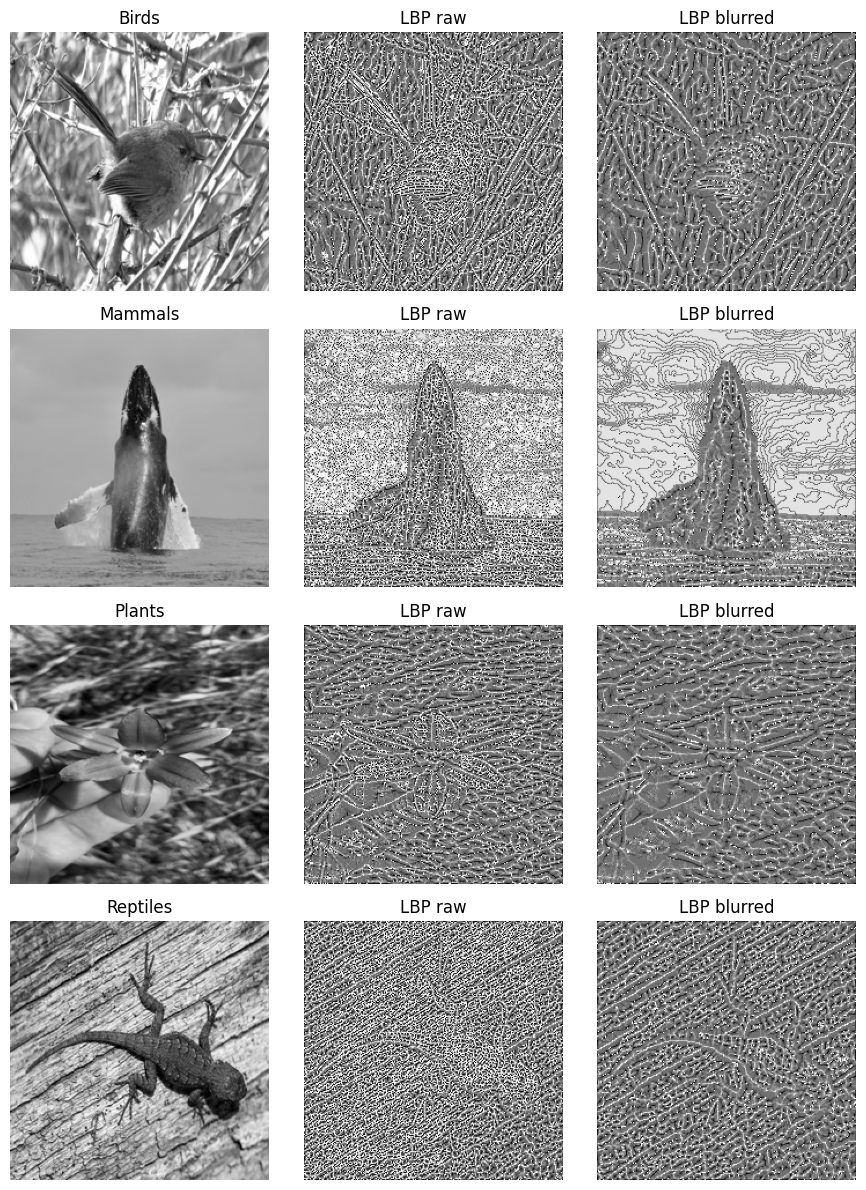

In [ ]:
sample = metadata.groupby(LABEL_COLUMN).sample(n=1, random_state=1).iloc[[3, 6, 8, 10]]  # Birds, Mammals, Plants, Reptiles
fig, axs = plt.subplots(4, 3, figsize=(9, 12))
for ax_row, (_, row) in zip(axs, sample.iterrows()):
    gray = np.array(Image.open(IMG_DIR / row["file_name"]).convert("L").resize((IMG_SIZE, IMG_SIZE)))
    ax_row[0].imshow(gray, cmap="gray"); ax_row[0].set_title(row[LABEL_COLUMN])
    ax_row[1].imshow(local_binary_pattern(gray, 8, 1, method="uniform"), cmap="gray"); ax_row[1].set_title("LBP raw")
    ax_row[2].imshow(local_binary_pattern(blur(gray), 8, 1, method="uniform"), cmap="gray"); ax_row[2].set_title("LBP blurred")
for ax in axs.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Signal test

Same stratified split as before (15% test held out). 5-fold CV on the rest with standardized logistic regression. Chance is 1/11 = 9%.

In [ ]:
idx = np.arange(len(y))
idx_dev, idx_test = train_test_split(idx, test_size=0.15, stratify=y, random_state=SEED)

sets = {"color": feats["color"]}
for k in ["lbp_raw", "lbp_blur", "lbp_center", "lbp_grid"]:
    sets[k] = feats[k]
for k in ["lbp_raw", "lbp_blur", "lbp_center", "lbp_grid"]:
    sets[f"color + {k}"] = np.hstack([feats["color"], feats[k]])

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
make_clf = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

rows = []
for name, X in sets.items():
    r = cross_validate(make_clf(), X[idx_dev], y[idx_dev], cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({"features": name, "dims": X.shape[1],
                 "acc": r["test_accuracy"].mean(), "acc std": r["test_accuracy"].std(),
                 "macro-F1": r["test_f1_macro"].mean()})
results = pd.DataFrame(rows).set_index("features")
print(f"chance = {1 / len(categories):.3f}")
results.round(3)

chance = 0.091


,dims,acc,acc std,macro-F1
features,,,,
color,48,0.194,0.033,0.184
lbp_raw,54,0.258,0.014,0.252
lbp_blur,54,0.241,0.025,0.234
lbp_center,54,0.217,0.015,0.211
lbp_grid,216,0.174,0.016,0.173
color + lbp_raw,102,0.267,0.014,0.259
color + lbp_blur,102,0.244,0.027,0.235
color + lbp_center,102,0.245,0.030,0.236
color + lbp_grid,264,0.195,0.015,0.192


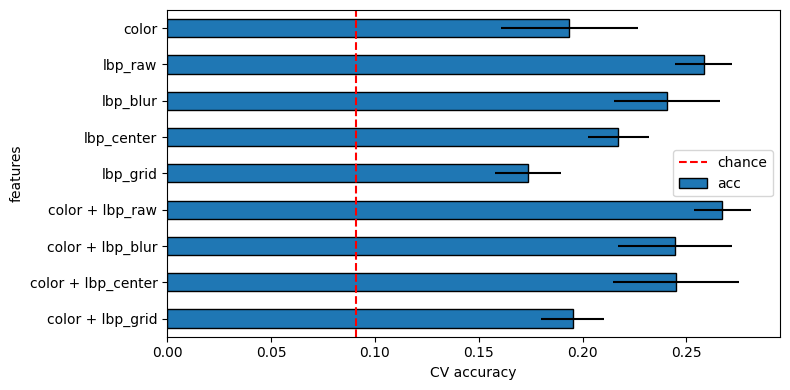

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
results["acc"].plot.barh(xerr=results["acc std"], ax=ax, edgecolor="black")
ax.axvline(1 / len(categories), color="red", ls="--", label="chance")
ax.invert_yaxis(); ax.set_xlabel("CV accuracy"); ax.legend()
plt.tight_layout()
plt.show()

## 5. Confusion Matrix

Row-normalized confusion matrix (out-of-fold predictions) for the best feature set.

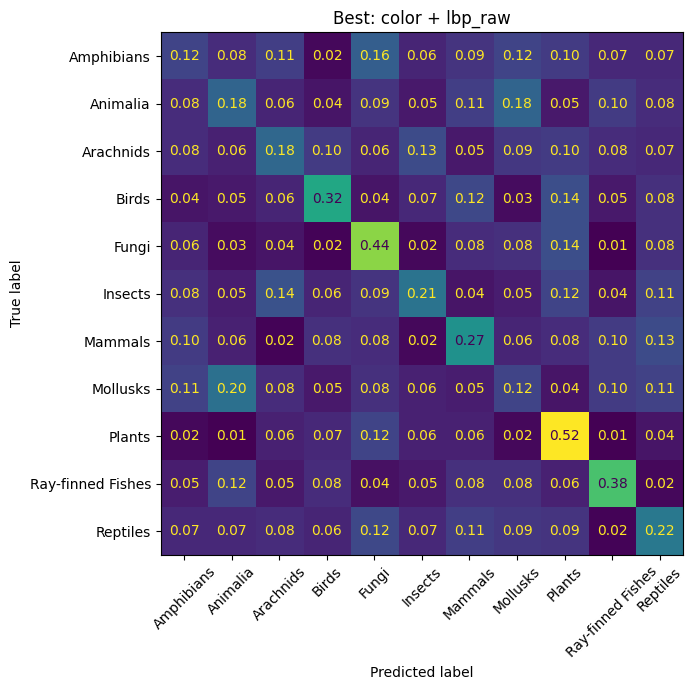

In [ ]:
best = results["macro-F1"].idxmax()
pred = cross_val_predict(make_clf(), sets[best][idx_dev], y[idx_dev], cv=cv, n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y[idx_dev], pred, labels=categories, normalize="true"),
                       display_labels=categories).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
ax.set_title(f"Best: {best}")
plt.tight_layout()
plt.show()

## 6. Save

In [ ]:
np.savez(FEATURE_DIR / "lbp_color_features.npz", y=y, image_id=metadata["image_id"].to_numpy(),
         idx_dev=idx_dev, idx_test=idx_test, **feats)
print("Saved", FEATURE_DIR / "lbp_color_features.npz")

Saved features/lbp_color_features.npz


## Notes

(fill in: does blur/center/grid help, does LBP add anything on top of color, which classes are still confused)